In [1]:
#Task 1: MSE and RMSE for Zomato delivery times
import numpy as np

actual = np.array([58, 46, 34, 33, 42, 24, 31, 39, 48, 50])
pred = np.array([59, 46, 42, 30, 43, 17, 34, 34, 50, 55])

mse = np.mean((actual - pred) ** 2)
rmse = np.sqrt(mse)

print("MSE:", mse)
print("RMSE:", rmse)

MSE: 18.7
RMSE: 4.324349662087931


In [2]:
#Task 2: MAE and R2 score for Flipkart price prediction
from sklearn.metrics import mean_absolute_error, r2_score

act_p = [2295, 952, 1061, 2872, 979, 735, 2425, 732, 2757, 2052]
pred_p = [2264, 993, 1135, 2736, 748, 836, 2178, 531, 2582, 2040]

def get_scores(a, p):
    mae = mean_absolute_error(a, p)
    r2 = r2_score(a, p)
    return mae, r2

mae, r2 = get_scores(act_p, pred_p)
print("MAE:", mae)
print("R2 score:", r2)

MAE: 124.9
R2 score: 0.9675315572732787


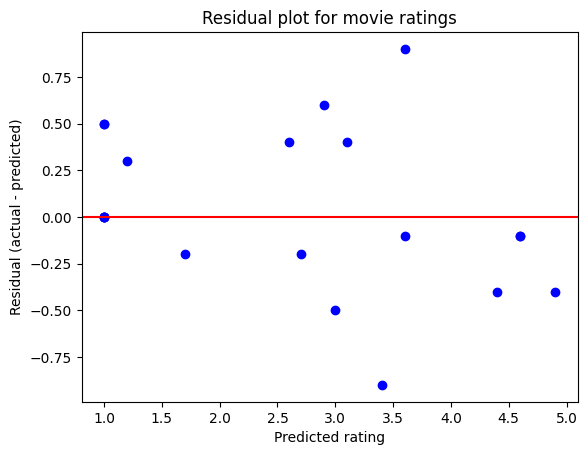

In [3]:
#Task 3: Residual plot for movie ratings
import matplotlib.pyplot as plt

act_r = np.array([1.0, 1.5, 3.5, 4.5, 3.0, 3.5, 1.0, 2.5, 4.5, 1.5, 3.5, 2.5, 4.5, 4.5, 1.5, 1.0, 4.0, 1.5, 2.5, 1.0])
pred_r = np.array([1.0, 1.0, 3.1, 4.9, 2.6, 2.9, 1.0, 3.4, 4.6, 1.2, 3.6, 2.7, 4.6, 3.6, 1.7, 1.0, 4.4, 1.0, 3.0, 1.0])

res = act_r - pred_r

plt.scatter(pred_r, res, color="blue")
plt.axhline(0, color="red")
plt.xlabel("Predicted rating")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual plot for movie ratings")
plt.show()

# The points are spread above and below the zero line with no clear pattern, so the errors look random and the model is fitting fine.
# The biggest mistakes are about 0.9 away from zero (for example actual 4.5 but predicted 3.6), so no single point is far off.

### Task 4: Which model to choose for Swiggy delivery time

Model A has RMSE 8 minutes and R2 0.65. Model B has RMSE 6 minutes and R2 0.55.

I would choose Model B. RMSE is in minutes, so it tells us directly that Model B is off by about 6 minutes on a typical order, while Model A is off by about 8 minutes. For delivery time, a smaller error in minutes is what matters to the customer.

R2 only tells how much of the variation in delivery time the model explains. It depends on how spread out the data is, so it is harder to read in real terms. Model A has a better R2, but its predictions are further from the real time.

One more point: if both models were tested on the same data, a lower RMSE would also give a higher R2. Since here they disagree, the two models were most likely tested on different data. So before the final decision, I would test both on the same test set and check again.

In [4]:
#Task 5: Compare two models for Spotify song popularity (MSE, RMSE, MAE, R2)
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sp = pd.read_csv("spotify_songs.csv")
X = sp[["danceability", "energy", "tempo"]]
y = sp["popularity"]
xtr, xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1)

def show(name, model):
    model.fit(xtr, ytr)
    for part, xx, yy in [("train", xtr, ytr), ("test", xte, yte)]:
        p = model.predict(xx)
        mse = mean_squared_error(yy, p)
        print(name, part, "-> MSE:", round(mse, 2), "RMSE:", round(mse ** 0.5, 2),
              "MAE:", round(mean_absolute_error(yy, p), 2), "R2:", round(r2_score(yy, p), 3))

show("Linear Regression", LinearRegression())
show("Decision Tree", DecisionTreeRegressor(random_state=1))

# The Decision Tree is the one overfitting. Its train MSE is 0 and R2 is 1.0, but on test data MSE jumps to about 52 and R2 falls to about 0.36.
# Linear Regression has a train and test error that are much closer (test R2 about 0.60), and its test error is lower, so it generalises better.

Linear Regression train -> MSE: 22.67 RMSE: 4.76 MAE: 3.73 R2: 0.834
Linear Regression test -> MSE: 32.54 RMSE: 5.7 MAE: 4.55 R2: 0.595
Decision Tree train -> MSE: 0.0 RMSE: 0.0 MAE: 0.0 R2: 1.0
Decision Tree test -> MSE: 51.83 RMSE: 7.2 MAE: 5.63 R2: 0.355
